In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('UpdatedResumeDataSet.csv')

In [3]:
df.sample(5)

,Category,Resume
731,Database,TECHNICAL EXPERTISE â¢ DB Languages: SQL â¢ ...
598,Python Developer,â¢ Operating Systems: Windows â¢ Others: MS ...
273,Health and fitness,Personal Skills: â¢ Good verbal and written c...
517,Operations Manager,IT SKILLS â¢ Well versed with MS Office and I...
12,Data Science,"Areas of Interest Deep Learning, Control Syste..."


In [4]:
df.isnull().sum()

Category    0
Resume      0
dtype: int64

In [5]:
df['Category']

0      Data Science
1      Data Science
2      Data Science
3      Data Science
4      Data Science
           ...     
957         Testing
958         Testing
959         Testing
960         Testing
961         Testing
Name: Category, Length: 962, dtype: object

<Axes: ylabel='Category'>

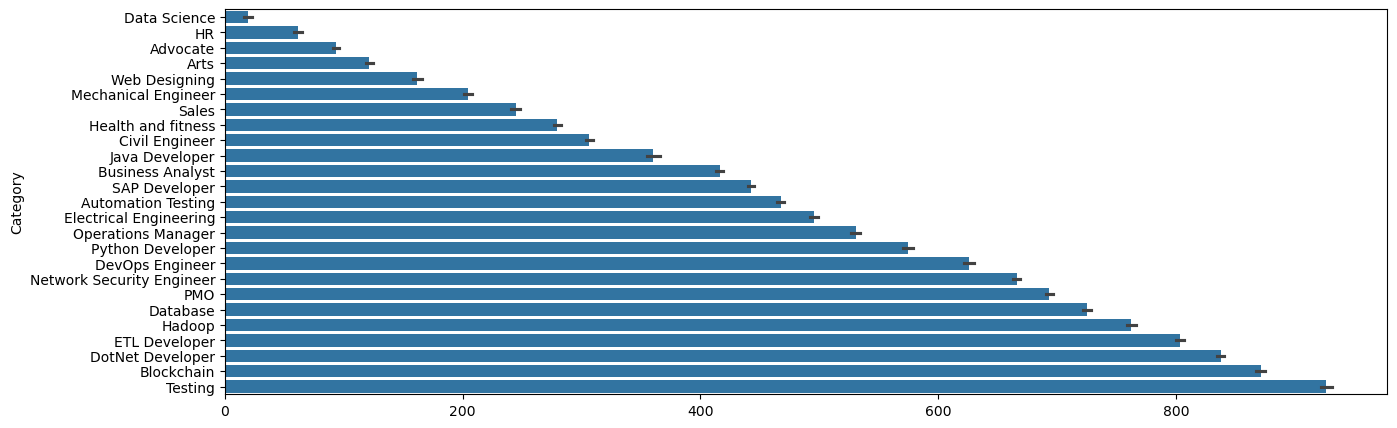

In [6]:
plt.figure(figsize=(15,5))
sns.barplot(df['Category'])

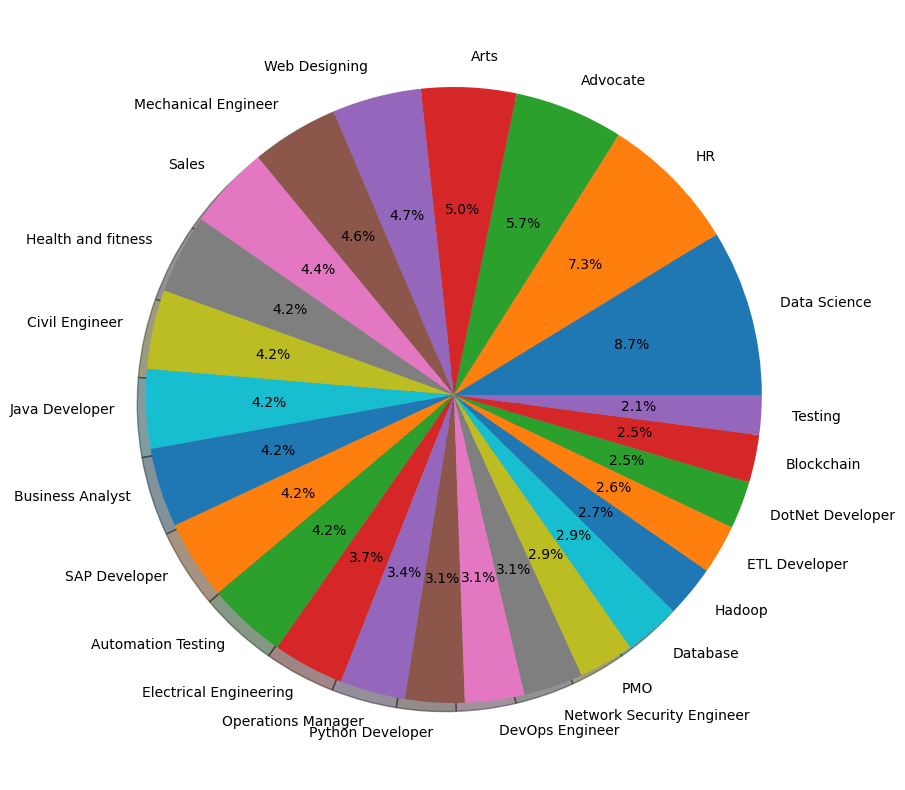

In [7]:
plt.figure(figsize=(15,10))
count = df['Category'].value_counts()
labels = df['Category'].unique()
plt.pie(count,labels=labels,shadow=True,autopct='%1.1f%%')
plt.show()

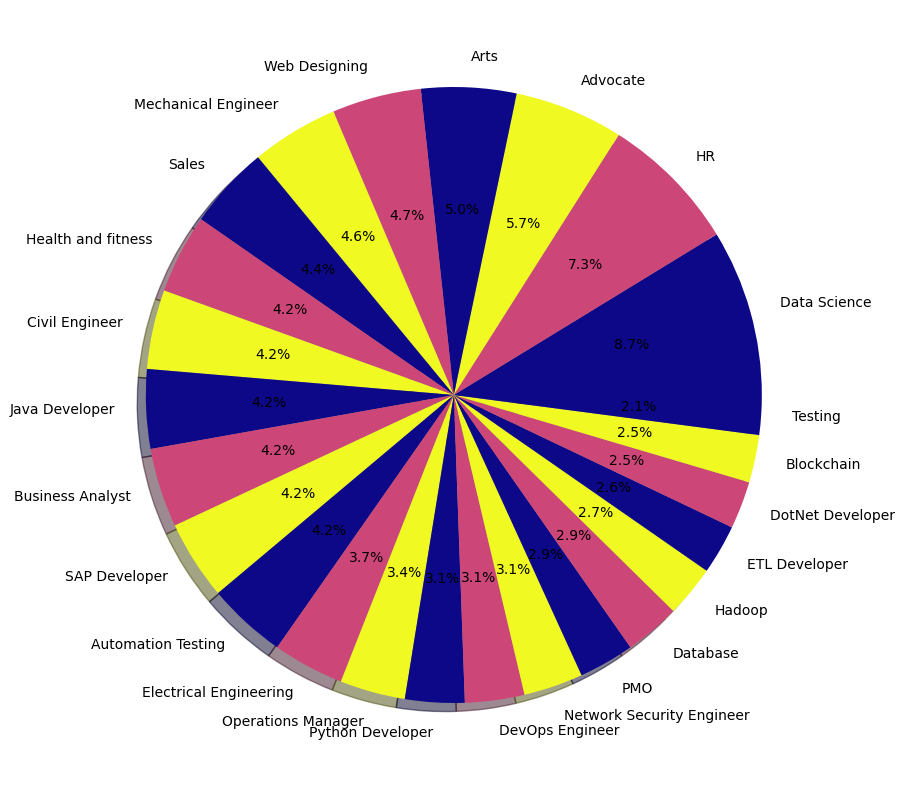

In [8]:
plt.figure(figsize=(15,10))
count = df['Category'].value_counts()
labels = df['Category'].unique()
plt.pie(count,labels=labels,shadow=True,autopct='%1.1f%%',colors=plt.cm.plasma(np.linspace(0,1,3)))
plt.show()

In [9]:
df['Category'].unique()

array(['Data Science', 'HR', 'Advocate', 'Arts', 'Web Designing',
       'Mechanical Engineer', 'Sales', 'Health and fitness',
       'Civil Engineer', 'Java Developer', 'Business Analyst',
       'SAP Developer', 'Automation Testing', 'Electrical Engineering',
       'Operations Manager', 'Python Developer', 'DevOps Engineer',
       'Network Security Engineer', 'PMO', 'Database', 'Hadoop',
       'ETL Developer', 'DotNet Developer', 'Blockchain', 'Testing'],
      dtype=object)

In [10]:
df

,Category,Resume
0,Data Science,Skills * Programming Languages: Python (pandas...
1,Data Science,Education Details \r\nMay 2013 to May 2017 B.E...
2,Data Science,"Areas of Interest Deep Learning, Control Syste..."
3,Data Science,Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...
4,Data Science,"Education Details \r\n MCA YMCAUST, Faridab..."
...,...,...
957,Testing,Computer Skills: â¢ Proficient in MS office (...
958,Testing,â Willingness to accept the challenges. â ...
959,Testing,"PERSONAL SKILLS â¢ Quick learner, â¢ Eagerne..."
960,Testing,COMPUTER SKILLS & SOFTWARE KNOWLEDGE MS-Power ...


## Now we will remove the unwanted things in resume column for example ,@# et'cetra

In [11]:
df['Category'][0]

'Data Science'

In [12]:
df['Resume'][0]

'Skills * Programming Languages: Python (pandas, numpy, scipy, scikit-learn, matplotlib), Sql, Java, JavaScript/JQuery. * Machine learning: Regression, SVM, NaÃ¯ve Bayes, KNN, Random Forest, Decision Trees, Boosting techniques, Cluster Analysis, Word Embedding, Sentiment Analysis, Natural Language processing, Dimensionality reduction, Topic Modelling (LDA, NMF), PCA & Neural Nets. * Database Visualizations: Mysql, SqlServer, Cassandra, Hbase, ElasticSearch D3.js, DC.js, Plotly, kibana, matplotlib, ggplot, Tableau. * Others: Regular Expression, HTML, CSS, Angular 6, Logstash, Kafka, Python Flask, Git, Docker, computer vision - Open CV and understanding of Deep learning.Education Details \r\n\r\nData Science Assurance Associate \r\n\r\nData Science Assurance Associate - Ernst & Young LLP\r\nSkill Details \r\nJAVASCRIPT- Exprience - 24 months\r\njQuery- Exprience - 24 months\r\nPython- Exprience - 24 monthsCompany Details \r\ncompany - Ernst & Young LLP\r\ndescription - Fraud Investigatio

In [13]:
# print('original distribution') 
# print(df['Category'].value_counts())

# # maximum entry of category
# max_entry = df['Category'].value_counts().max()

# balanced_df = df.groupby('Category').apply(lambda x: x.sample(max_entry,replace=True).reset_index(drop=True))
# df = balanced_df.sample(frac=1).reset_index(drop=True)

# # check the oversampling distribution
# print('\n Balance The Distribution (Over Sampling)')
# print(df['Category'].value_counts())

# Clean Data

##### 1.URls,
##### 2.Hashtag,
##### 3.Mensions,
##### 4.Special letters,
##### 5.Punctuation:


In [14]:
import re

def CleanResume(txt):
    CleanText=re.sub('http\S+\s','',txt)
    CleanText=re.sub('#\S+\s', '',CleanText)
    CleanText=re.sub('@\S+','', CleanText)
    CleanText=re.sub('RT|cc', '', CleanText)
    #CleanText=re.sub('[%s]' % re.escape("""~!@#$%^&*()_+{|}[\]:;./''<>?+=-"""),'',CleanText)
    CleanText=re.sub('[%s]' % re.escape("""!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~"""),'',CleanText)
    CleanText=re.sub(r'[^\x00-\x7f]' ,'', CleanText)
    CleanText=re.sub('\s+',' ',CleanText)

    return CleanText

In [15]:
CleanResume('my name is khan @hostel,#college,  #@&@*@()}{"|][][/.,; uwy https//:www.go.com so this $ is all the \n stuf jhfd ')

'my name is khan uwy so this is all the stuf jhfd '

In [16]:
CleanResume(df['Resume'][0])

'Skills Programming Languages Python pandas numpy scipy scikitlearn matplotlib Sql Java JavaScriptJQuery Machine learning Regression SVM Nave Bayes KNN Random Forest Decision Trees Boosting techniques Cluster Analysis Word Embedding Sentiment Analysis Natural Language processing Dimensionality reduction Topic Modelling LDA NMF PCA Neural Nets Database Visualizations Mysql SqlServer Cassandra Hbase ElasticSearch D3js DCjs Plotly kibana matplotlib ggplot Tableau Others Regular Expression HTML CSS Angular 6 Logstash Kafka Python Flask Git Docker computer vision Open CV and understanding of Deep learningEducation Details Data Science Assurance Associate Data Science Assurance Associate Ernst Young LLP Skill Details JAVASCRIPT Exprience 24 months jQuery Exprience 24 months Python Exprience 24 monthsCompany Details company Ernst Young LLP description Fraud Investigations and Dispute Services Assurance TECHNOLOGY ASSISTED REVIEW TAR Technology Assisted Review assists in aelerating the review 

In [17]:
df['Resume'] = df['Resume'].apply(lambda x:CleanResume(x))

In [18]:
df['Resume'][0]

'Skills Programming Languages Python pandas numpy scipy scikitlearn matplotlib Sql Java JavaScriptJQuery Machine learning Regression SVM Nave Bayes KNN Random Forest Decision Trees Boosting techniques Cluster Analysis Word Embedding Sentiment Analysis Natural Language processing Dimensionality reduction Topic Modelling LDA NMF PCA Neural Nets Database Visualizations Mysql SqlServer Cassandra Hbase ElasticSearch D3js DCjs Plotly kibana matplotlib ggplot Tableau Others Regular Expression HTML CSS Angular 6 Logstash Kafka Python Flask Git Docker computer vision Open CV and understanding of Deep learningEducation Details Data Science Assurance Associate Data Science Assurance Associate Ernst Young LLP Skill Details JAVASCRIPT Exprience 24 months jQuery Exprience 24 months Python Exprience 24 monthsCompany Details company Ernst Young LLP description Fraud Investigations and Dispute Services Assurance TECHNOLOGY ASSISTED REVIEW TAR Technology Assisted Review assists in aelerating the review 

In [19]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
le.fit(df['Category'])
df['Category'] = le.transform(df['Category'])

In [20]:
df

,Category,Resume
0,6,Skills Programming Languages Python pandas num...
1,6,Education Details May 2013 to May 2017 BE UITR...
2,6,Areas of Interest Deep Learning Control System...
3,6,Skills R Python SAP HANA Tableau SAP HANA SQL ...
4,6,Education Details MCA YMCAUST Faridabad Haryan...
...,...,...
957,23,Computer Skills Proficient in MS office Word B...
958,23,Willingness to aept the challenges Positive t...
959,23,PERSONAL SKILLS Quick learner Eagerness to lea...
960,23,COMPUTER SKILLS SOFTWARE KNOWLEDGE MSPower Poi...


In [21]:
df['Category'].unique()

array([ 6, 12,  0,  1, 24, 16, 22, 14,  5, 15,  4, 21,  2, 11, 18, 20,  8,
       17, 19,  7, 13, 10,  9,  3, 23])

In [26]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.multiclass import OneVsOneClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (accuracy_score,classification_report,confusion_matrix)

# Original text and labels
X = df['Resume']
y = df['Category']

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create Pipeline
model = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english')),
    ('classifier', OneVsOneClassifier(KNeighborsClassifier()))
])

# Train
model.fit(X_train, y_train)

# Predictions
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

# Accuracy
print("Training Accuracy:",accuracy_score(y_train, train_pred) * 100)

print("Testing Accuracy:",accuracy_score(y_test, test_pred) * 100)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, test_pred))

# Cross Validation
scores = cross_val_score( model,X_train,y_train,cv=5,scoring='accuracy')

print("\n5-Fold CV Scores:", scores)
print("Average CV Accuracy:", scores.mean() * 100)

Training Accuracy: 99.21976592977893
Testing Accuracy: 98.96373056994818

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         7
           2       0.80      0.80      0.80         5
           3       1.00      1.00      1.00         8
           4       1.00      1.00      1.00         6
           5       1.00      1.00      1.00         5
           6       1.00      1.00      1.00         8
           7       1.00      1.00      1.00         7
           8       1.00      0.91      0.95        11
           9       1.00      1.00      1.00         5
          10       1.00      1.00      1.00         8
          11       0.86      1.00      0.92         6
          12       1.00      1.00      1.00         9
          13       1.00      1.00      1.00         8
          14       1.00      1.00      1.00         6
          15       1.00      1.00     

In [30]:
my_resume = """I am a data scientist specializing in machine
learning, deep learning, and computer vision. With
a strong background in mathematics, statistics,
and programming, I am passionate about
uncovering hidden patterns and insights in data.
I have extensive experience in developing
predictive models, implementing deep learning
algorithms, and designing computer vision
systems. My technical skills include proficiency in
Python, Sklearn, TensorFlow, and PyTorch.
What sets me apart is my ability to effectively
communicate complex concepts to diverse
audiences. I excel in translating technical insights
into actionable recommendations that drive
informed decision-making.
If you're looking for a dedicated and versatile data
scientist to collaborate on impactful projects, I am
eager to contribute my expertise. Let's harness the
power of data together to unlock new possibilities
and shape a better future.
Contact & Sources
Email: 611noorsaeed@gmail.com
Phone: 03442826192
Github: https://github.com/611noorsaeed
Linkdin: https://www.linkedin.com/in/noor-saeed654a23263/
Blogs: https://medium.com/@611noorsaeed
Youtube: Artificial Intelligence
ABOUT ME
WORK EXPERIENCE
SKILLES
NOOR SAEED
LANGUAGES
English
Urdu
Hindi
I am a versatile data scientist with expertise in a wide
range of projects, including machine learning,
recommendation systems, deep learning, and computer
vision. Throughout my career, I have successfully
developed and deployed various machine learning models
to solve complex problems and drive data-driven
decision-making
Machine Learnine
Deep Learning
Computer Vision
Recommendation Systems
Data Visualization
Programming Languages (Python, SQL)
Data Preprocessing and Feature Engineering
Model Evaluation and Deployment
Statistical Analysis
Communication and Collaboration
""" 
print(CleanResume(my_resume))

I am a data scientist specializing in machine learning deep learning and computer vision With a strong background in mathematics statistics and programming I am passionate about uncovering hidden patterns and insights in data I have extensive experience in developing predictive models implementing deep learning algorithms and designing computer vision systems My technical skills include proficiency in Python Sklearn TensorFlow and PyTorch What sets me apart is my ability to effectively communicate complex concepts to diverse audiences I excel in translating technical insights into actionable recommendations that drive informed decisionmaking If youre looking for a dedicated and versatile data scientist to collaborate on impactful projects I am eager to contribute my expertise Lets harness the power of data together to unlock new possibilities and shape a better future Contact Sources Email 611noorsaeed Phone 03442826192 Github Linkdin Blogs Youtube Artificial Intelligence ABOUT ME WORK

In [28]:
# # Save File

import pickle

pickle.dump(model, open('resume_model.pkl', 'wb'))

In [34]:
model = pickle.load(open('resume_model.pkl', 'rb'))

CleanedResume = CleanResume(my_resume)

prediction_id = model.predict([CleanedResume])[0]


In [35]:
Category_mapping = {
    6: 'Data Science',
    12: 'HR',
    0: 'Advocate',
    1: 'Arts',
    24: 'Web Designing',
    16: 'Mechanical Engineer',
    22: 'Sales',
    14: 'Health And Fitness',
    5: 'Civil Engineer',
    15: 'Java Developer',
    4: 'Business Analyst',
    21: 'SAP Developer',
    2: 'Automation Testing',
    11: 'Electrical Engineer',
    18: 'Operation Manager',
    20: 'Python Developer',
    8: 'DevOps',
    17: 'Network Security',
    19: 'PMO',
    7: 'Database',
    13: 'Hadoop',
    10: 'ETL Developer',
    9: 'Dot Net Developer',
    3: 'BlockChain',
    23: 'Testing'

}

In [36]:
Category_name = Category_mapping.get(prediction_id,'Unknown')
print('Resume is:-',Category_name)
prediction_id

Resume is:- Data Science


np.int64(6)